In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Importing Files

In [2]:
def lowerColName(df):
    df.columns = [i.lower() for i in df.columns]
    return df.columns

customers = pd.read_csv('datasets/customers.csv')
customers.columns = lowerColName(customers)

sales = pd.read_csv('datasets/sales.csv')
sales.columns = lowerColName(sales)

products = pd.read_csv('datasets/products.csv')
products.columns = lowerColName(products)

#### Understanding the files

In [3]:
customers.head()

,customer_id,customer_name,gender,age,age_group,date_of_birth,email,phone,city,state,pincode,registration_date,customer_tier,total_orders,total_spent
0,CUST00000001,Akash Agarwal,male,48,46-55,1977-01-13,akashagarwal@gmail.com,+91-9625152011,Patiala,Punjab,122521,2024-01-28,Gold,5,40098.48
1,CUST00000002,Farhan Rahman,male,73,65+,1952-01-20,farhanrahman@gmail.com,+91-8593009465,Durgapur,West Bengal,226518,2023-08-25,Platinum,8,63676.24
2,CUST00000003,Suresh Kumar,male,31,26-35,1994-01-09,sureshkumar755@gmail.com,+91-7935884774,Gurugram,Haryana,520400,2023-08-30,Silver,0,0.00
3,CUST00000004,Aditya Pandey,male,41,36-45,1984-01-12,adityapandey@outlook.com,+91-9015046072,Kolkata,West Bengal,735356,2024-03-11,Platinum,5,288324.84
4,CUST00000005,Hina Khan,female,53,46-55,1972-01-15,hinakhan433@gmail.com,+91-8813094271,Noida,UP,985141,2024-04-19,Platinum,4,69265.75


In [4]:
products.head()

,product_id,product_name,category,brand,original_price,discount_percent,discount_amount,selling_price,stock_quantity,weight_kg,avg_rating,total_reviews
0,PROD000001,Samsung Mobile V5,Electronics,Samsung,130561.34,23,30029.11,100532.23,159,2.63,4.49,102
1,PROD000002,HP Laptop V5,Electronics,HP,36494.92,34,12408.27,24086.65,54,4.19,4.32,107
2,PROD000003,boAt Headphones V2,Electronics,boAt,106587.94,42,44766.93,61821.01,638,1.48,4.31,99
3,PROD000004,Noise Watch V7,Electronics,Noise,81275.27,47,38199.38,43075.89,572,3.30,4.42,127
4,PROD000005,Apple iPhone V4,Electronics,Apple,13099.36,43,5632.72,7466.64,865,3.71,4.37,98


In [5]:
sales.head()

,order_id,customer_id,product_id,order_date,order_time,delivery_date,quantity,unit_price,order_value,shipping_cost,...,coupon_discount,total_amount,payment_mode,order_status,rating,review_text,city,state,customer_age,customer_age_group
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,2622.46,2622.46,0.0,...,0.0,2622.46,COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,90258.00,90258.00,0.0,...,0.0,90258.00,COD,Delivered,4.0,Nice quality,Durgapur,West Bengal,22,18-25
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,3536.50,3536.50,0.0,...,0.0,3536.50,UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,34081.56,34081.56,0.0,...,50.0,34031.56,Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,69021.17,138042.34,0.0,...,0.0,138042.34,UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45


In [6]:
print(sales.shape, customers.shape, products.shape)

(250000, 21) (40000, 15) (2000, 12)


#### Working on Customers Table

In [7]:
customers.describe()

,age,pincode,total_orders,total_spent
count,40000.000000,40000.000000,40000.000000,40000.00000
mean,35.306225,549135.098375,5.003475,118539.15886
std,12.581443,259430.688860,2.232485,106205.42346
min,18.000000,100010.000000,0.000000,0.00000
25%,26.000000,325689.750000,3.000000,37814.14750
50%,33.000000,547573.500000,5.000000,90059.66000
75%,43.000000,773876.000000,6.000000,169958.41750
max,75.000000,999986.000000,17.000000,890131.55000


In [8]:
customers.isnull().sum()

customer_id          0
customer_name        0
gender               0
age                  0
age_group            0
date_of_birth        0
email                0
phone                0
city                 0
state                0
pincode              0
registration_date    0
customer_tier        0
total_orders         0
total_spent          0
dtype: int64

In [9]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        40000 non-null  str    
 1   customer_name      40000 non-null  str    
 2   gender             40000 non-null  str    
 3   age                40000 non-null  int64  
 4   age_group          40000 non-null  str    
 5   date_of_birth      40000 non-null  str    
 6   email              40000 non-null  str    
 7   phone              40000 non-null  str    
 8   city               40000 non-null  str    
 9   state              40000 non-null  str    
 10  pincode            40000 non-null  int64  
 11  registration_date  40000 non-null  str    
 12  customer_tier      40000 non-null  str    
 13  total_orders       40000 non-null  int64  
 14  total_spent        40000 non-null  float64
dtypes: float64(1), int64(3), str(11)
memory usage: 8.8 MB


* Making the decision to drop columns - age_group, date_of_birth, phone
* Change the datatype of column age to int8/int16, and total_orders to int8

In [10]:
customers.drop(columns=['age_group','date_of_birth','phone'], inplace=True)

In [ ]:
customers.age = customers.age.astype(np.int8)
customers.total_orders = customers.total_orders.astype(np.int8)

#### Working with Sales Table

In [12]:
sales.describe()

,quantity,unit_price,order_value,shipping_cost,coupon_discount,total_amount,rating,customer_age
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,120030.000000,250000.000000
mean,1.249580,19202.477645,23967.862192,4.911971,250.001146,23722.773017,4.399400,35.309416
std,0.535689,26720.495176,37629.320529,18.141581,1399.928532,37267.644163,0.663915,12.574524
min,1.000000,26.130000,26.130000,0.000000,0.000000,-21.560000,3.000000,18.000000
25%,1.000000,1551.550000,1825.890000,0.000000,0.000000,1803.900000,4.000000,26.000000
50%,1.000000,7208.930000,8411.160000,0.000000,0.000000,8339.490000,4.000000,33.000000
75%,1.000000,24433.270000,28612.810000,0.000000,0.000000,28344.920000,5.000000,43.000000
max,3.000000,136973.330000,410919.990000,90.000000,41092.000000,410919.990000,5.000000,75.000000


In [13]:
sales.isnull().sum().sort_values(ascending=False)

coupon_code           199815
review_text           129970
rating                129970
customer_id                0
order_id                   0
order_time                 0
order_date                 0
product_id                 0
delivery_date              0
order_value                0
shipping_cost              0
unit_price                 0
quantity                   0
total_amount               0
coupon_discount            0
order_status               0
payment_mode               0
city                       0
state                      0
customer_age               0
customer_age_group         0
dtype: int64

* Handling Null Values
    - coupon code: NotApplicable
    - review text: NotProvided
    - rating: Replacing with the average of all ratings

In [14]:
sales.coupon_code = sales.coupon_code.fillna("NOT APPLICABLE")
sales.review_text = sales.review_text.fillna("NOT APPLICABLE")

avgRating = sales.rating.dropna().mean()
sales.rating = sales.rating.fillna(avgRating)

In [15]:
sales.rating.mean()

np.float64(4.39940014996251)

In [16]:
sales.rating.unique()

array([4.39940015, 4.        , 5.        , 3.        ])

In [17]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            250000 non-null  str    
 1   customer_id         250000 non-null  str    
 2   product_id          250000 non-null  str    
 3   order_date          250000 non-null  str    
 4   order_time          250000 non-null  str    
 5   delivery_date       250000 non-null  str    
 6   quantity            250000 non-null  int64  
 7   unit_price          250000 non-null  float64
 8   order_value         250000 non-null  float64
 9   shipping_cost       250000 non-null  float64
 10  coupon_code         250000 non-null  str    
 11  coupon_discount     250000 non-null  float64
 12  total_amount        250000 non-null  float64
 13  payment_mode        250000 non-null  str    
 14  order_status        250000 non-null  str    
 15  rating              250000 non-null  float64


* Change the datatype of quantity to int8 and rating to int8
* Dropping the columns - city, state, customer_age, customer_age_group - because they are already present in the customers table

In [18]:
sales.drop(columns=['city','state','customer_age','customer_age_group'], inplace=True)

In [19]:
sales.quantity = sales.quantity.astype(np.int8)
sales.rating = sales.rating.astype(np.int8)

#### Working with products table

In [20]:
products.describe()

,original_price,discount_percent,discount_amount,selling_price,stock_quantity,weight_kg,avg_rating,total_reviews
count,2000.000000,2000.000000,2000.00000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000
mean,18323.619210,27.471000,5143.28014,13180.33907,503.479000,2.640980,4.398185,60.015000
std,29472.155725,13.309874,9732.99126,21514.94963,287.140337,1.373574,0.095983,27.645161
min,52.250000,5.000000,6.29000,26.13000,10.000000,0.210000,3.910000,15.000000
25%,1522.505000,16.000000,332.26000,1088.03750,250.750000,1.430000,4.340000,38.000000
50%,4775.355000,27.000000,1154.91500,3543.41500,504.500000,2.725000,4.400000,54.000000
75%,22358.115000,39.000000,5452.93500,16063.81250,749.000000,3.790000,4.460000,78.000000
max,149658.640000,50.000000,71289.60000,136973.33000,1000.000000,5.000000,4.760000,139.000000


In [21]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        2000 non-null   str    
 1   product_name      2000 non-null   str    
 2   category          2000 non-null   str    
 3   brand             2000 non-null   str    
 4   original_price    2000 non-null   float64
 5   discount_percent  2000 non-null   int64  
 6   discount_amount   2000 non-null   float64
 7   selling_price     2000 non-null   float64
 8   stock_quantity    2000 non-null   int64  
 9   weight_kg         2000 non-null   float64
 10  avg_rating        2000 non-null   float64
 11  total_reviews     2000 non-null   int64  
dtypes: float64(5), int64(3), str(4)
memory usage: 261.2 KB


* Change the Datatype of column avg_ratings to float16 and total_reviews to int16 and weight_kg to float16 and stock_quantity to int32

In [22]:
products.avg_rating = products.avg_rating.astype(np.float16)
products.total_reviews = products.total_reviews.astype(np.int16)
products.weight_kg = products.weight_kg.astype(np.float16)
products.stock_quantity = products.stock_quantity.astype(np.int32)

In [23]:
products.isnull().sum()

product_id          0
product_name        0
category            0
brand               0
original_price      0
discount_percent    0
discount_amount     0
selling_price       0
stock_quantity      0
weight_kg           0
avg_rating          0
total_reviews       0
dtype: int64

# UNIVARIATE ANALYSIS on CUSTOMER table

### Summary of univariate analysis of the customer table

    - Platinum Members Dominate with strength of around 2/3rd
    - Males and Females are EQUALLY present
    - Majority of the puchases are of low value items, < 100000 Rs
    - Many Customers Fall in the age group of [20-35]

In [24]:
customers.columns

Index(['customer_id', 'customer_name', 'gender', 'age', 'email', 'city',
       'state', 'pincode', 'registration_date', 'customer_tier',
       'total_orders', 'total_spent'],
      dtype='str')

Text(0.5, 1.0, 'UNIVARIATE ANALYSIS ON AGE')

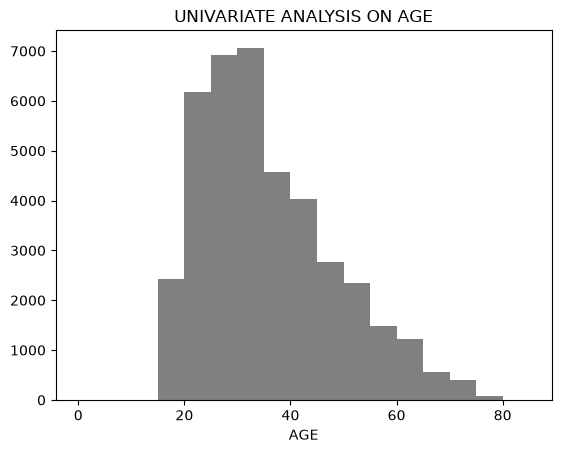

In [25]:
plt.hist(customers.age, bins=[0,5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85], color='grey')
plt.xlabel("AGE")
plt.title("UNIVARIATE ANALYSIS ON AGE")

<Axes: xlabel='age', ylabel='Density'>

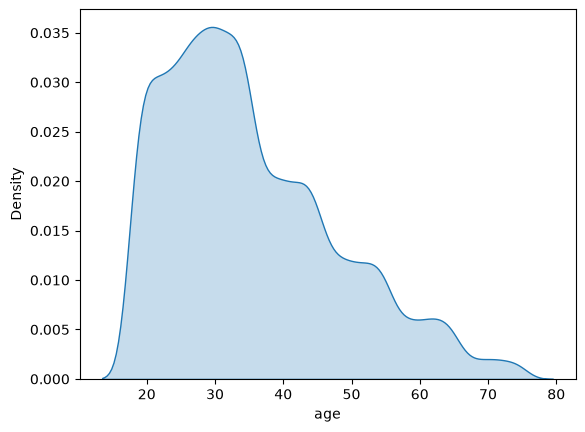

In [26]:
sns.kdeplot(customers.age, fill=True)

* Many Customers Fall in the age group of [20-35]

Text(0.5, 1.0, 'UNIVARIATE ANALYSIS ON TOTAL SPENT')

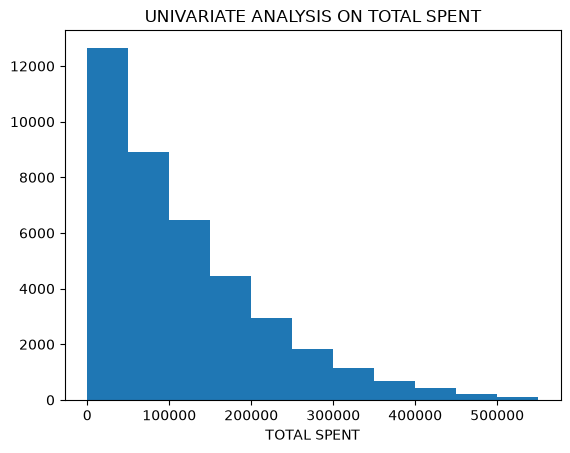

In [27]:
plt.hist(customers.total_spent, bins=[0,50000,100000,150000,200000,250000,300000,350000,400000,450000,500000,550000])
plt.xlabel("TOTAL SPENT")
plt.title("UNIVARIATE ANALYSIS ON TOTAL SPENT")

<Axes: xlabel='total_spent', ylabel='Density'>

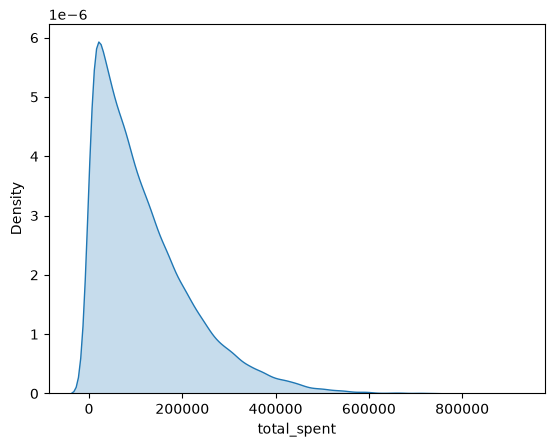

In [28]:
sns.kdeplot(customers.total_spent, fill=True)

* Majority of the puchases are of low value items, < 100000 Rs

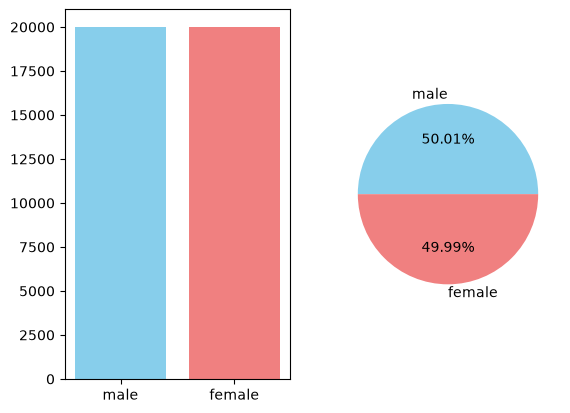

In [29]:
gender_counts = customers.gender.value_counts()

fig, ax = plt.subplots(nrows=1, ncols=2)
ax[0].bar(gender_counts.index, gender_counts.values, color=['skyblue', 'lightcoral'])
ax[1].pie(gender_counts.values, labels=gender_counts.index, colors=['skyblue', 'lightcoral'], autopct='%0.2f%%')

* Males and Females are EQUALLY present

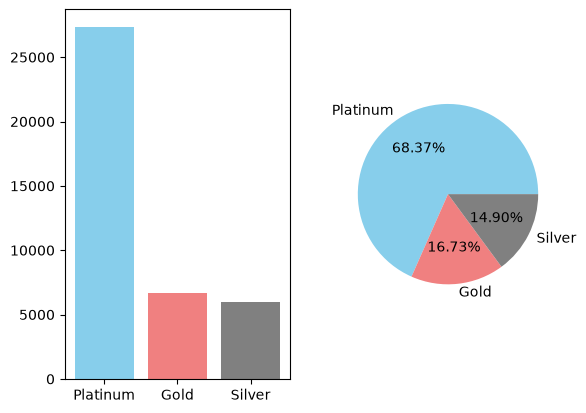

In [30]:
customer_tier_counts = customers.customer_tier.value_counts()

fig, ax = plt.subplots(nrows=1, ncols=2)
ax[0].bar(customer_tier_counts.index, customer_tier_counts.values, color=['skyblue', 'lightcoral', 'grey'])
ax[1].pie(customer_tier_counts.values, labels=customer_tier_counts.index, colors=['skyblue', 'lightcoral', 'grey'], autopct='%0.2f%%')

* Platinum Members Dominate with strength of around 2/3rd

# UNIVARIATE ANALYSIS on SALES table

### Summary of univariate analysis of the sales table

    - Majority (almost all) of the items are shipped at ZERO COST
    - Almost half (51.4%) payments are done through UPI, followed by COD (32.9%)
    - Delivery
        * 80 Percent of the orders are delivered.
        * Cancelled and Returened makes 10 percent of the orders
    - LEAST NUMBER Of Products Got NEGATIVE review
    - Month
        * Maximum Orders are recieved in the month of June.
        * Rest all months have recieved alsmost same number of orders 
    - Time
        * Almost every hour sees equal number of orders
        * Around 22 percent orders are placed in afternoon (12pm to 5pm)
        * Early Morning (5am to 8am) and midnight (9pm to 12pm) observes least number of orders

In [31]:
sales.columns

Index(['order_id', 'customer_id', 'product_id', 'order_date', 'order_time',
       'delivery_date', 'quantity', 'unit_price', 'order_value',
       'shipping_cost', 'coupon_code', 'coupon_discount', 'total_amount',
       'payment_mode', 'order_status', 'rating', 'review_text'],
      dtype='str')

(array([232459.,      0.,      0.,      0.,      0.,   1760.,   3917.,
          3955.,   3994.,   3915.]),
 array([ 0.,  9., 18., 27., 36., 45., 54., 63., 72., 81., 90.]),
 <BarContainer object of 10 artists>)

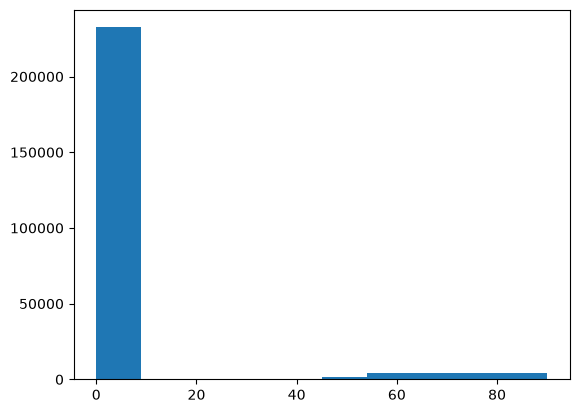

In [32]:
plt.hist(sales.shipping_cost)

<Axes: xlabel='shipping_cost', ylabel='Density'>

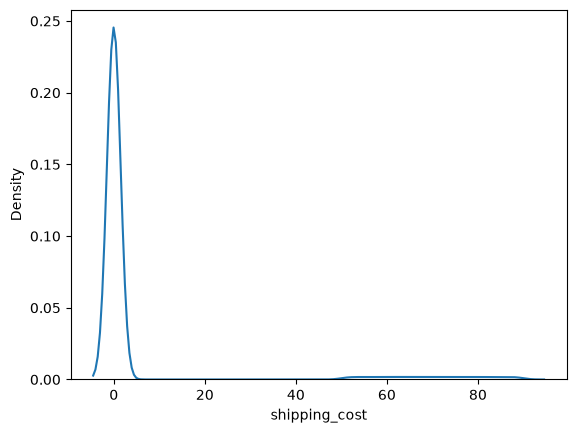

In [33]:
sns.kdeplot(sales.shipping_cost)

In [34]:
sales.shipping_cost.value_counts()

shipping_cost
0.00     232459
78.81        14
70.35        14
57.23        13
77.46        13
          ...  
58.44         1
65.31         1
65.58         1
80.42         1
68.82         1
Name: count, Length: 3938, dtype: int64

* Majority (almost all) of the items are shipped at ZERO COST

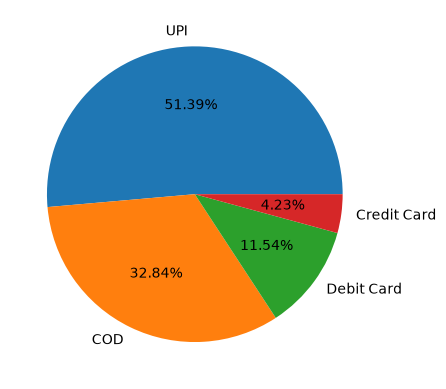

In [35]:
payment_mode_count = sales.payment_mode.value_counts()
plt.pie(payment_mode_count.values, labels=payment_mode_count.index, autopct='%0.2f%%')

* Almost half (51.4%) payments are done through UPI, followed by COD (32.9%)

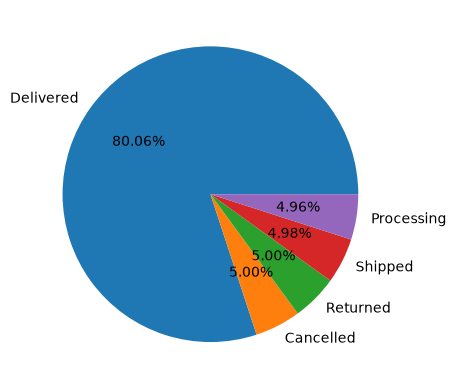

In [36]:
order_status_counts = sales.order_status.value_counts()
plt.pie(order_status_counts.values, labels=order_status_counts.index, autopct='%0.2f%%')

* 80 Percent of the orders are delivered.
* Cancelled and Returened makes 10 percent of the orders

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'Amazing quality!'),
  Text(1, 0, 'Highly recommended!'),
  Text(2, 0, 'Excellent product!'),
  Text(3, 0, 'Value for money'),
  Text(4, 0, 'Nice quality'),
  Text(5, 0, 'Good product'),
  Text(6, 0, 'Could be better'),
  Text(7, 0, 'Okay'),
  Text(8, 0, 'Average product')])

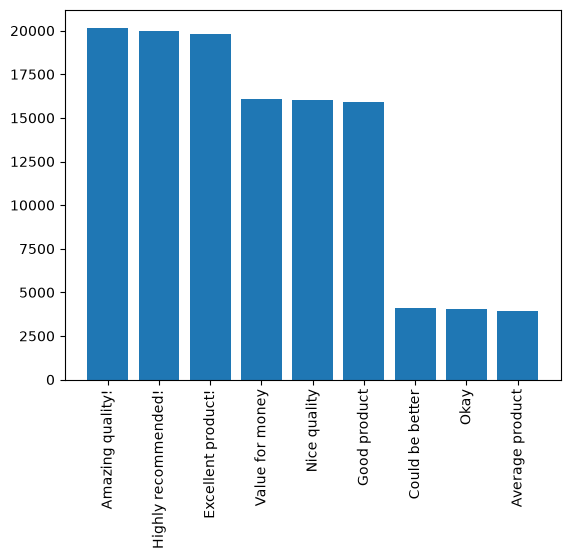

In [37]:
temp = sales[~(sales.review_text == 'NOT APPLICABLE')]
review_counts = temp.review_text.value_counts()

plt.bar(review_counts.index, review_counts.values)
plt.xticks(rotation='vertical')

* LEAST NUMBER Of Products Got NEGATIVE review

In [38]:
sales.columns

Index(['order_id', 'customer_id', 'product_id', 'order_date', 'order_time',
       'delivery_date', 'quantity', 'unit_price', 'order_value',
       'shipping_cost', 'coupon_code', 'coupon_discount', 'total_amount',
       'payment_mode', 'order_status', 'rating', 'review_text'],
      dtype='str')

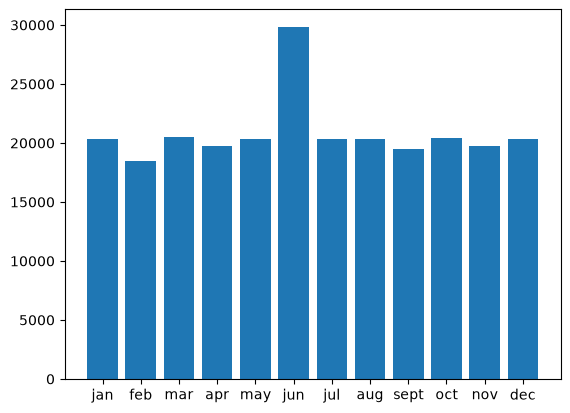

In [39]:
# Working on order_date
sales['sale_month'] = sales.order_date.apply(lambda x: int(x.split('-')[1]))
sorted(sales.sale_month.unique())

sale_month_count = sales.sale_month.value_counts()
plt.bar(sale_month_count.index, sale_month_count.values)
plt.xticks([1,2,3,4,5,6,7,8,9,10,11,12], ['jan','feb','mar','apr','may','jun','jul','aug','sept','oct','nov','dec'])
plt.show()

* Maximum Orders are recieved in the month of June.
* Rest all months have recieved alsmost same number of orders 

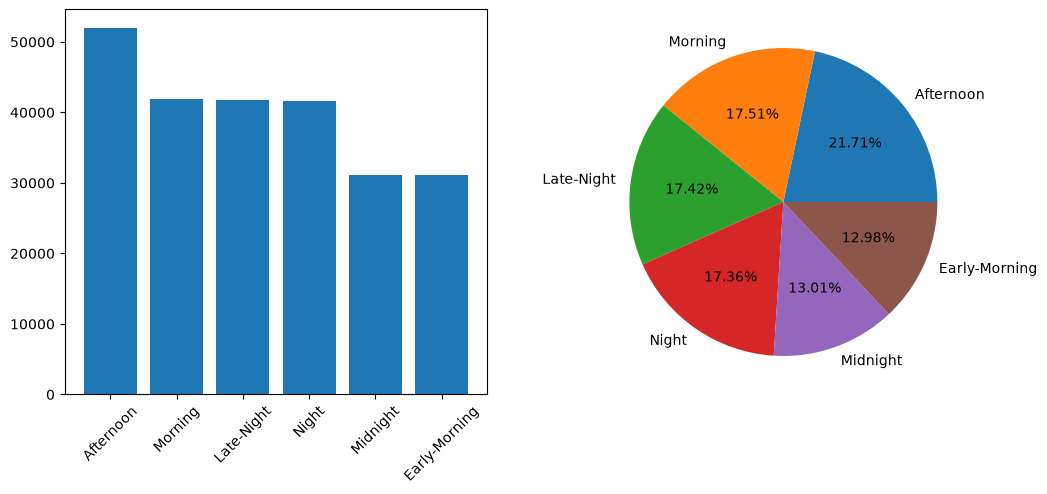

In [40]:
# Working on order time
def assignTimeStr(time):
    hr = int(time.split(':')[0])
    if hr > 0 and hr < 5:
        return 'Late-Night' 
    elif hr >= 5 and hr < 8:
        return 'Early-Morning'
    elif hr >= 8 and hr < 12:
        return 'Morning'
    elif hr >= 12 and hr < 17:
        return 'Afternoon'
    elif hr >= 17 and hr < 21:
        return 'Night'
    elif hr >= 21:
        return 'Midnight'
        

sales['time_group'] = sales.order_time.apply(assignTimeStr)

sale_time_group_count = sales.time_group.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(12, 5))
ax[0].bar(sale_time_group_count.index, sale_time_group_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(sale_time_group_count.values, labels=sale_time_group_count.index, autopct='%0.2f%%')


* Around 22 percent orders are placed in afternoon (12pm to 5pm)
* Early Morning (5am to 8am) and midnight (9pm to 12pm) observes least number of orders

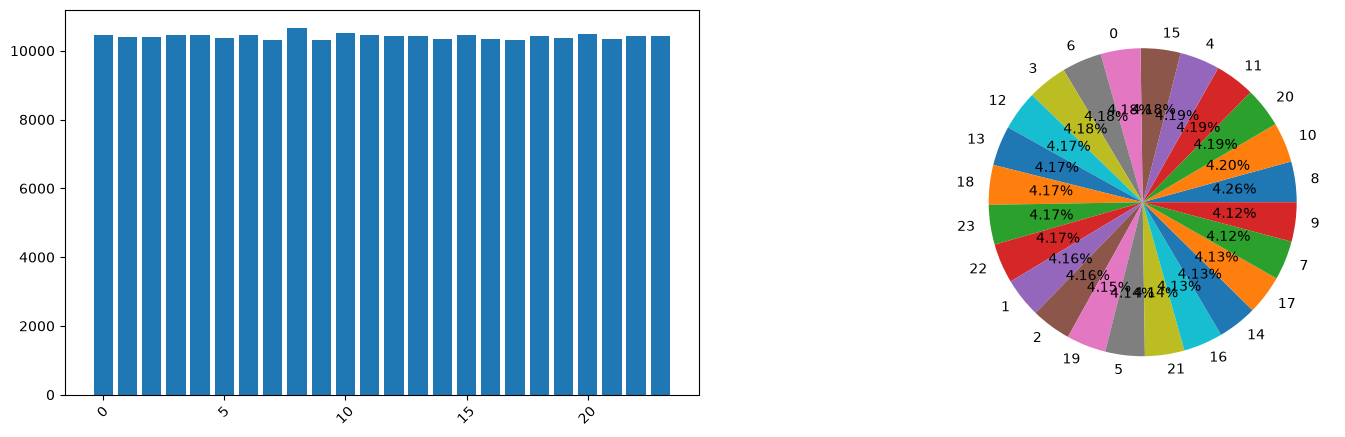

In [41]:
# Working on order_time
sales['time_int'] = sales.order_time.apply(lambda x: int(x.split(':')[0]))

sale_time_int_count = sales.time_int.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[0].bar(sale_time_int_count.index, sale_time_int_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(sale_time_int_count.values, labels=sale_time_int_count.index, autopct='%0.2f%%')

* Almost every hour sees equal number of orders

In [42]:
# Now I can drop - sale_month, time_group, time_int
sales.drop(columns=['sale_month', 'time_group', 'time_int'], inplace=True)

# UNIVARIATE ANALYSIS on PRODUCT table

### Summary of univariate analysis of the product table

    - All products are equally present
    - Top 7 Brands (as per the number of products present) with Nike and Puma leading
    - Ratings
        * The rating is Normally Distributed
        * Majority of the ratings falls 4.3 and 4.5

In [43]:
products.columns

Index(['product_id', 'product_name', 'category', 'brand', 'original_price',
       'discount_percent', 'discount_amount', 'selling_price',
       'stock_quantity', 'weight_kg', 'avg_rating', 'total_reviews'],
      dtype='str')

In [44]:
products.isnull().sum()

product_id          0
product_name        0
category            0
brand               0
original_price      0
discount_percent    0
discount_amount     0
selling_price       0
stock_quantity      0
weight_kg           0
avg_rating          0
total_reviews       0
dtype: int64

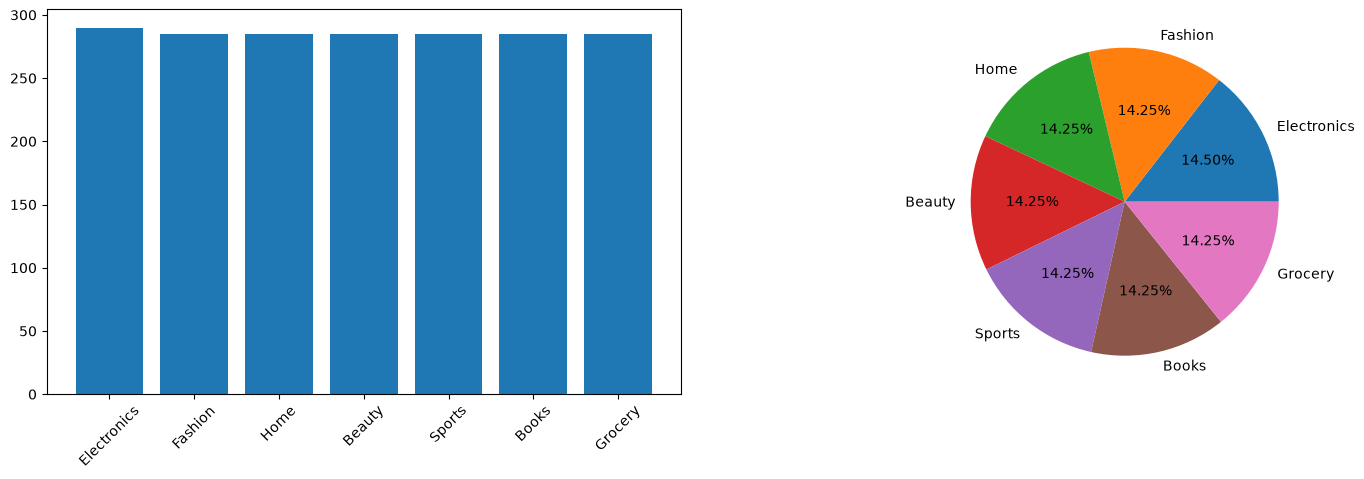

In [45]:
category_count = products.category.value_counts()

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[0].bar(category_count.index, category_count.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(category_count.values, labels=category_count.index, autopct='%0.2f%%')

* All products are equally present

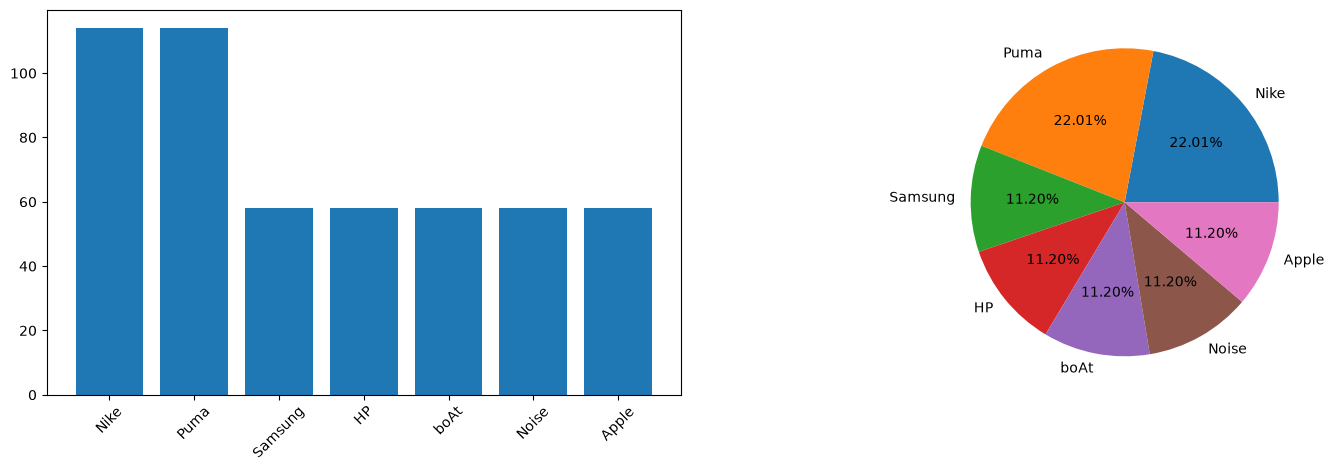

In [46]:
temp = products.brand.value_counts().sort_values(ascending=False).head(7)

fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(18, 5))
ax[0].bar(temp.index, temp.values)
ax[0].tick_params(axis='x', rotation=45)

ax[1].pie(temp.values, labels=temp.index, autopct='%0.2f%%')

* Top 7 Brands (as per the number of products present) with Nike and Puma leading

(array([  1.,   0.,   0.,   1.,   6.,   1.,  11.,  20.,  34.,  45., 103.,
        128., 182., 309., 293., 345., 186., 168.,  74.,  46.,  27.,   7.,
         10.,   2.,   1.]),
 array([3.91015625, 3.94335938, 3.97851562, 4.01171875, 4.046875  ,
        4.08203125, 4.11328125, 4.1484375 , 4.18359375, 4.21875   ,
        4.25      , 4.28515625, 4.3203125 , 4.3515625 , 4.38671875,
        4.421875  , 4.453125  , 4.48828125, 4.5234375 , 4.55859375,
        4.58984375, 4.625     , 4.66015625, 4.6953125 , 4.7265625 ,
        4.76171875]),
 <BarContainer object of 25 artists>)

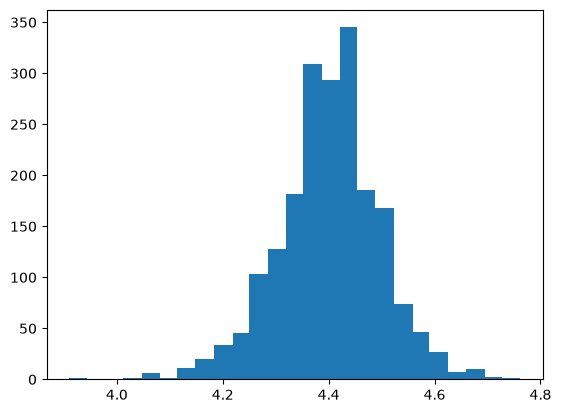

In [47]:
plt.hist(products.avg_rating, bins=25)

<Axes: xlabel='avg_rating', ylabel='Density'>

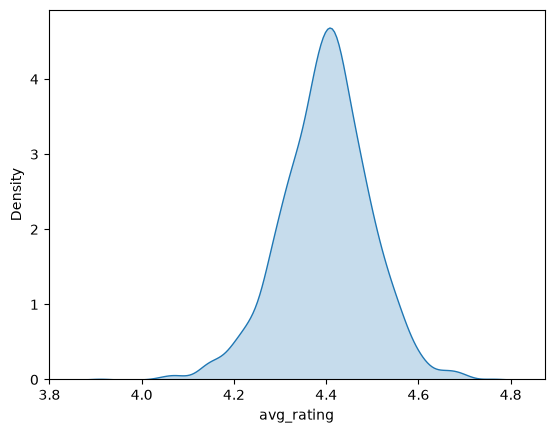

In [48]:
sns.kdeplot(products.avg_rating, fill=True)

* The rating is Normally Distributed
* Majority of the ratings falls 4.3 and 4.5

# BIVARIATE ANALYSIS on CUSTOMERS table

In [49]:
customers.columns

Index(['customer_id', 'customer_name', 'gender', 'age', 'email', 'city',
       'state', 'pincode', 'registration_date', 'customer_tier',
       'total_orders', 'total_spent'],
      dtype='str')

<Axes: xlabel='age', ylabel='Density'>

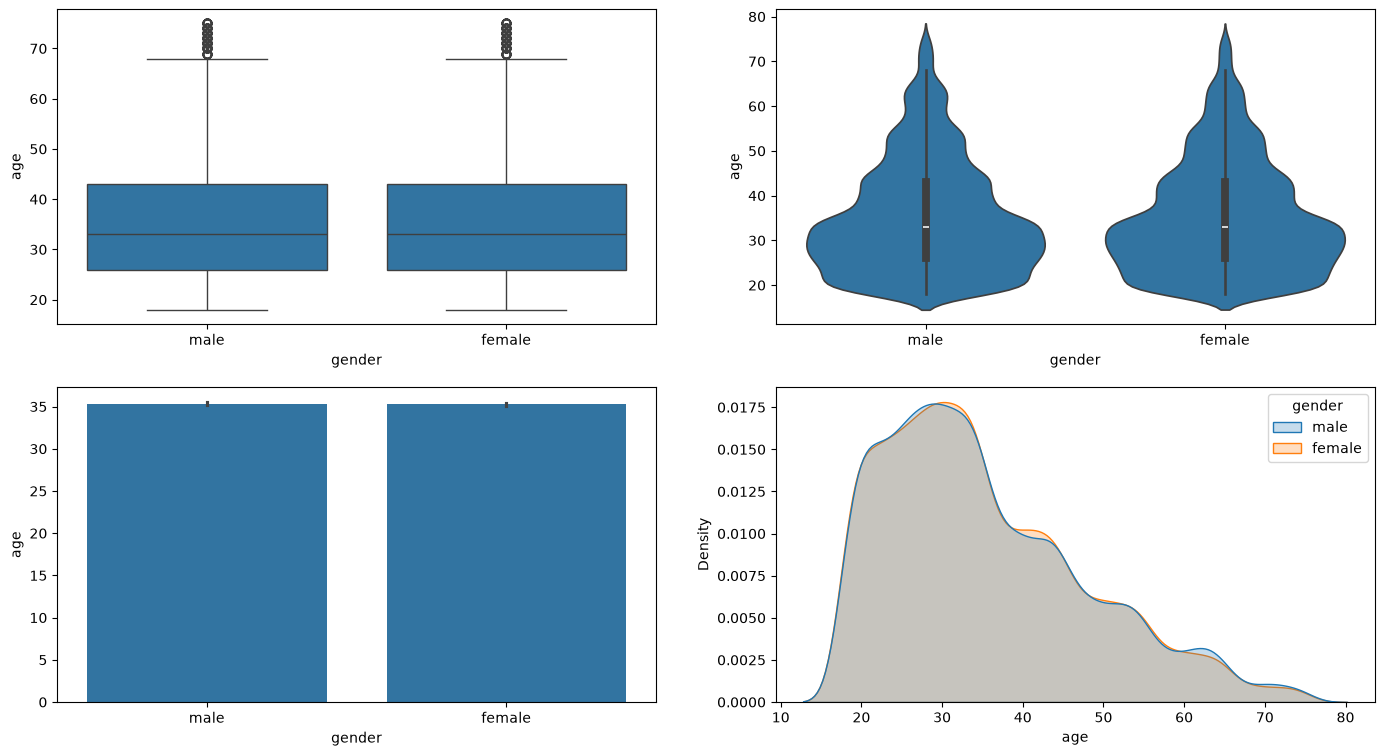

In [59]:
# Gender and Age
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='gender', y='age', ax=ax[0,0])
sns.violinplot(data=customers, x='gender', y='age', ax=ax[0,1])
sns.barplot(data=customers, x='gender', y='age', ax=ax[1,0])
sns.kdeplot(data=customers, x='age', hue='gender', fill=True)

* The distribution of age is identical between males and females. There isno relationship between AGE and GENDER
* There are a few outliers (boxplot)
* Average age of males and females are equal (around 35)
* Median age is around 32

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Punjab'),
  Text(1, 0, 'West Bengal'),
  Text(2, 0, 'Haryana'),
  Text(3, 0, 'UP'),
  Text(4, 0, 'Rajasthan'),
  Text(5, 0, 'Karnataka'),
  Text(6, 0, 'Maharashtra'),
  Text(7, 0, 'Delhi'),
  Text(8, 0, 'Tamil Nadu'),
  Text(9, 0, 'Gujarat')])

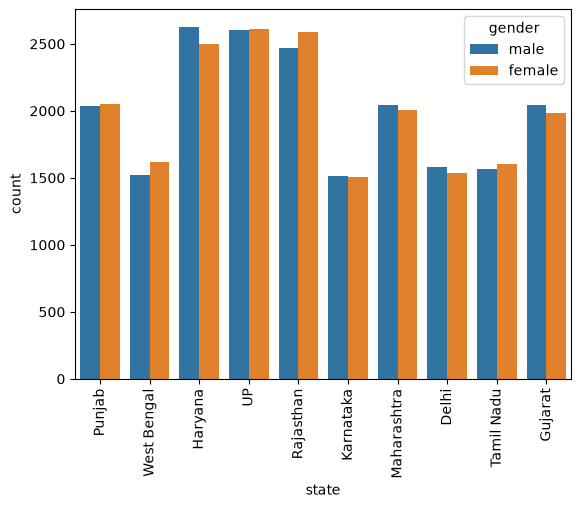

In [66]:
# Gender and State
sns.countplot(data=customers, x="state", hue="gender")
plt.xticks(rotation='vertical')

* Customers from UP, Haryana, Rajasthan dominate, followed by Maharastra and Gujarat (Central and North India)
* The distribution of males and females within a state is almost identical

([0, 1], [Text(0, 0, 'male'), Text(1, 0, 'female')])

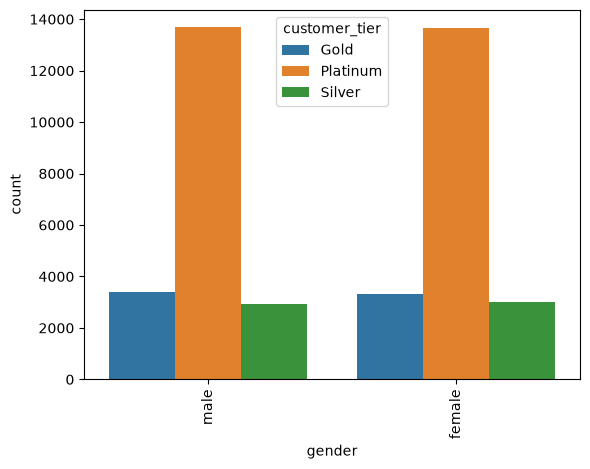

In [ ]:
# Gender and Customer Tier
sns.countplot(data=customers, x="gender", hue="customer_tier")
plt.xticks(rotation='vertical')

* Males and Females predominantly have PLATINUM membership

<Axes: xlabel='gender'>

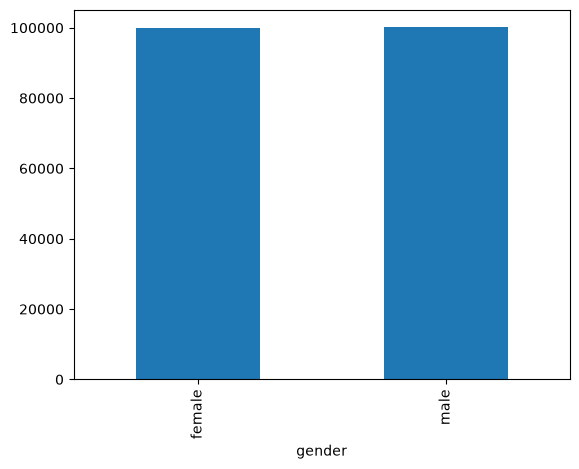

In [73]:
# Gender and total_orders
customers.groupby('gender')['total_orders'].sum().plot(kind='bar')

<Axes: xlabel='gender'>

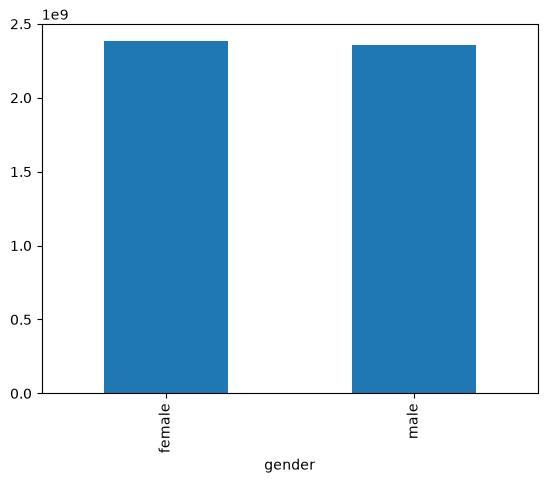

In [74]:
# Gender and total_spent
customers.groupby('gender')['total_spent'].sum().plot(kind='bar')

* Males and Females have spent equally and have ordered equally

<Axes: xlabel='state', ylabel='age'>

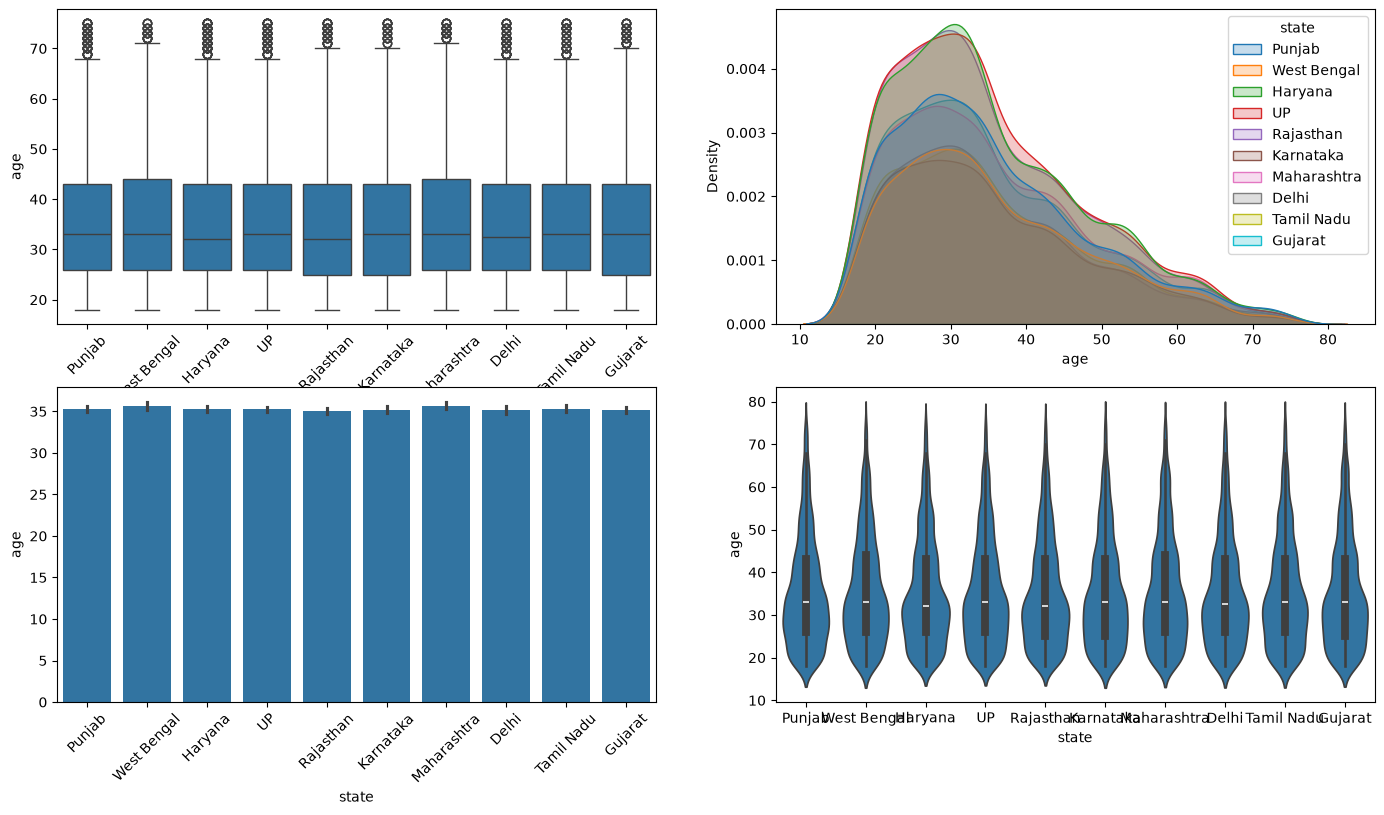

In [86]:
# Age and State
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='state', y='age', ax=ax[0,0])
ax[0,0].tick_params(axis='x', rotation=45)

sns.kdeplot(data=customers, x='age', hue='state', ax=ax[0,1], fill=True)

sns.barplot(data=customers, x='state', y='age',  ax=ax[1,0])
ax[1,0].tick_params(axis='x', rotation=45)

sns.violinplot(data=customers, x='state', y='age', ax=ax[1,1])

* Average age across the states are similar (around 35)
* There are a few outliers
* Data is right skewed, that is probability of a person being in the age group of 20-40 is more

<Axes: xlabel='customer_tier', ylabel='age'>

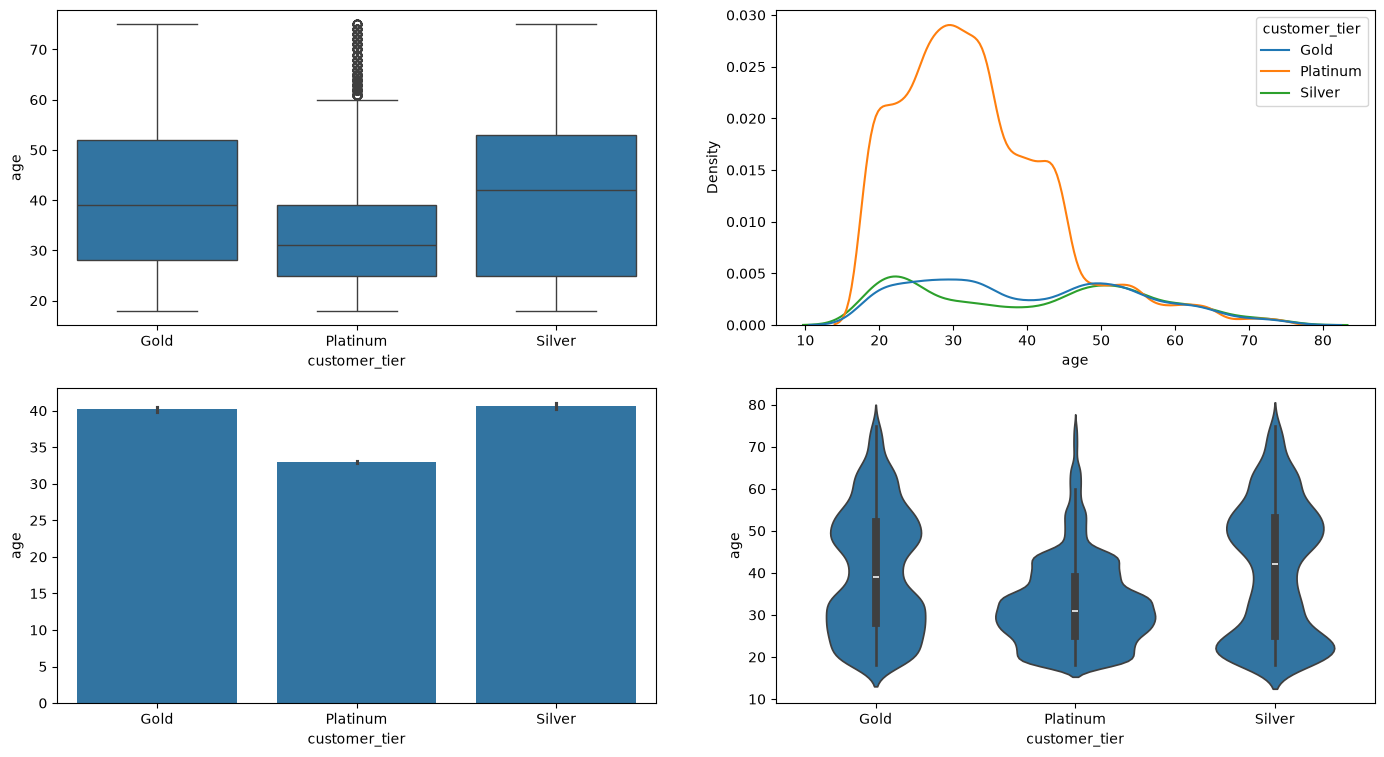

In [89]:
# Age and Customer Tier
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(17,9))

sns.boxplot(data=customers, x='customer_tier', y='age', ax=ax[0,0])
sns.kdeplot(data=customers, x='age', hue='customer_tier', ax=ax[0,1])
sns.barplot(data=customers, x='customer_tier', y='age',  ax=ax[1,0])
sns.violinplot(data=customers, x='customer_tier', y='age', ax=ax[1,1])

* Gold Tier
    - Median Age around 39
    - Average Age around 40
    - Bimodal Distribution

* Platinum Tier
    - Median Age around 31
    - Average Age around 33
    - Have lots of outliers >60
    - They are relatively younger
    - Right skewed
    - Customers are concentrated more in the age group 20-40

* Silver Tier
    - Median Age around 42
    - Average Age around 40.5
    - Bimodal Distribution

<Axes: xlabel='total_orders', ylabel='age'>

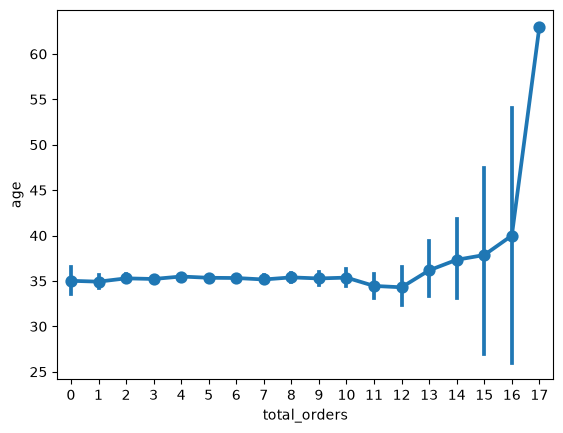

In [ ]:
# Age and Total Orders
sns.pointplot(data=customers, x='total_orders', y='age')

<Axes: xlabel='total_orders', ylabel='age'>

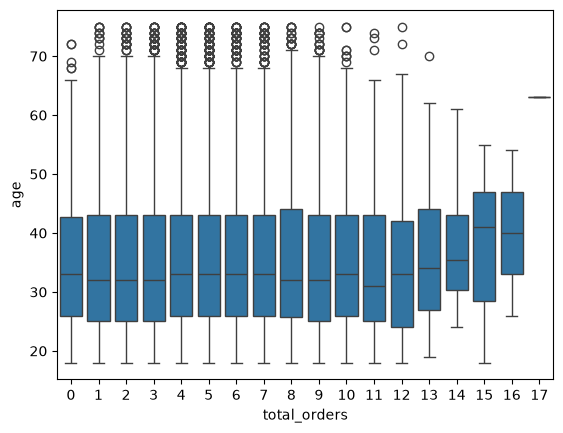

In [ ]:
sns.boxplot(data=customers, x="total_orders", y="age")

* No Oberservation is possible for age with total orders

<Axes: xlabel='age_group', ylabel='total_spent'>

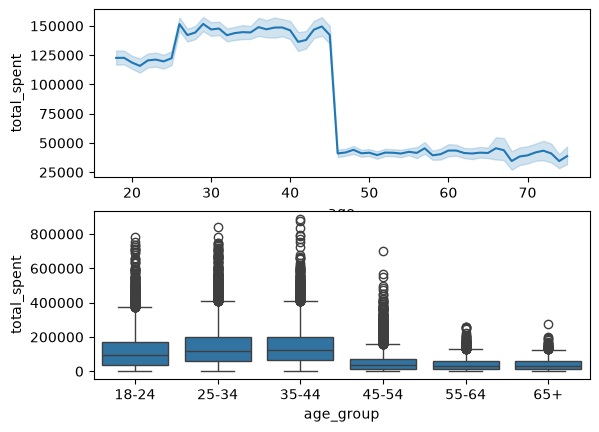

In [124]:
# Age with total spent
fig,ax=plt.subplots(nrows=2)

sns.lineplot(data=customers, x='age', y='total_spent', ax=ax[0])

bins = [18, 25, 35, 45, 55, 65, 80]
labels = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
customers["age_group"] = pd.cut(customers["age"], bins=bins, labels=labels, right=False)

sns.boxplot(data=customers, x="age_group", y="total_spent", ax=ax[1])

* Sharp Spending Drop at Age 45: Average customer spending drops dramatically around age 45, falling from ~140,000–150,000 for customers under 45 down to ~40,000 for those aged 46 and older.
* Interquartile range (IQR) compressing significantly after age 45, with the median spend collapsing from over ~120,000 to under ~40,000.
* While extreme spenders (>600k) are prevalent in the 18–44 groups and present in 45–54, spending above 300k virtually vanishes for customers aged 55+

<Axes: xlabel='customer_tier', ylabel='city'>

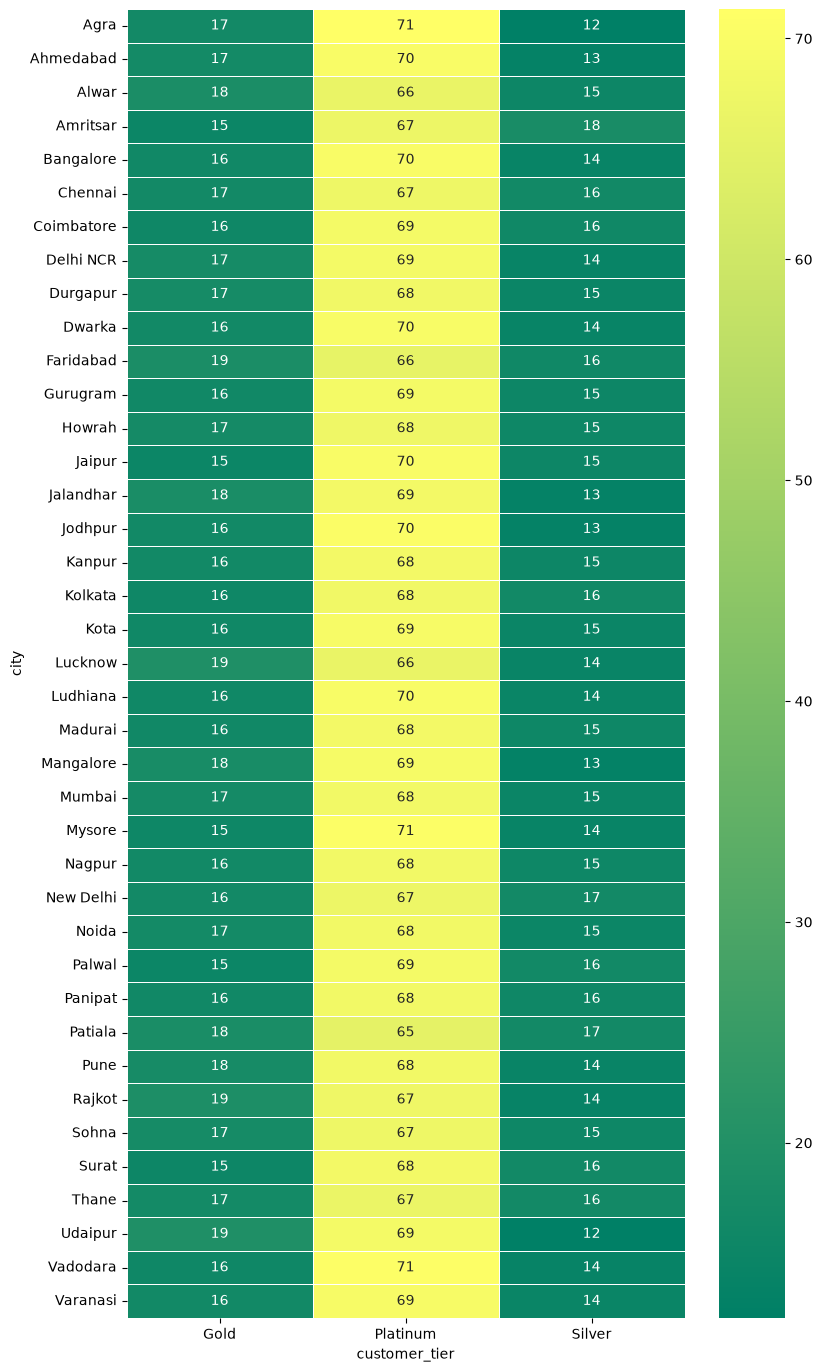

In [133]:
# city with customer_tire
grid = pd.crosstab(customers.city, customers.customer_tier, normalize="index")*100
plt.figure(figsize=(9,17))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

* No Geographic Dependency: There is no relationship between a customer's tier and the city in which they live.

* Consistent Distribution: Platinum accounts for roughly 65%–76% of memberships across all cities, while the remainder is split almost evenly between Gold (~15%–20%) and Silver (~12%–19%).

<Axes: xlabel='total_orders', ylabel='city'>

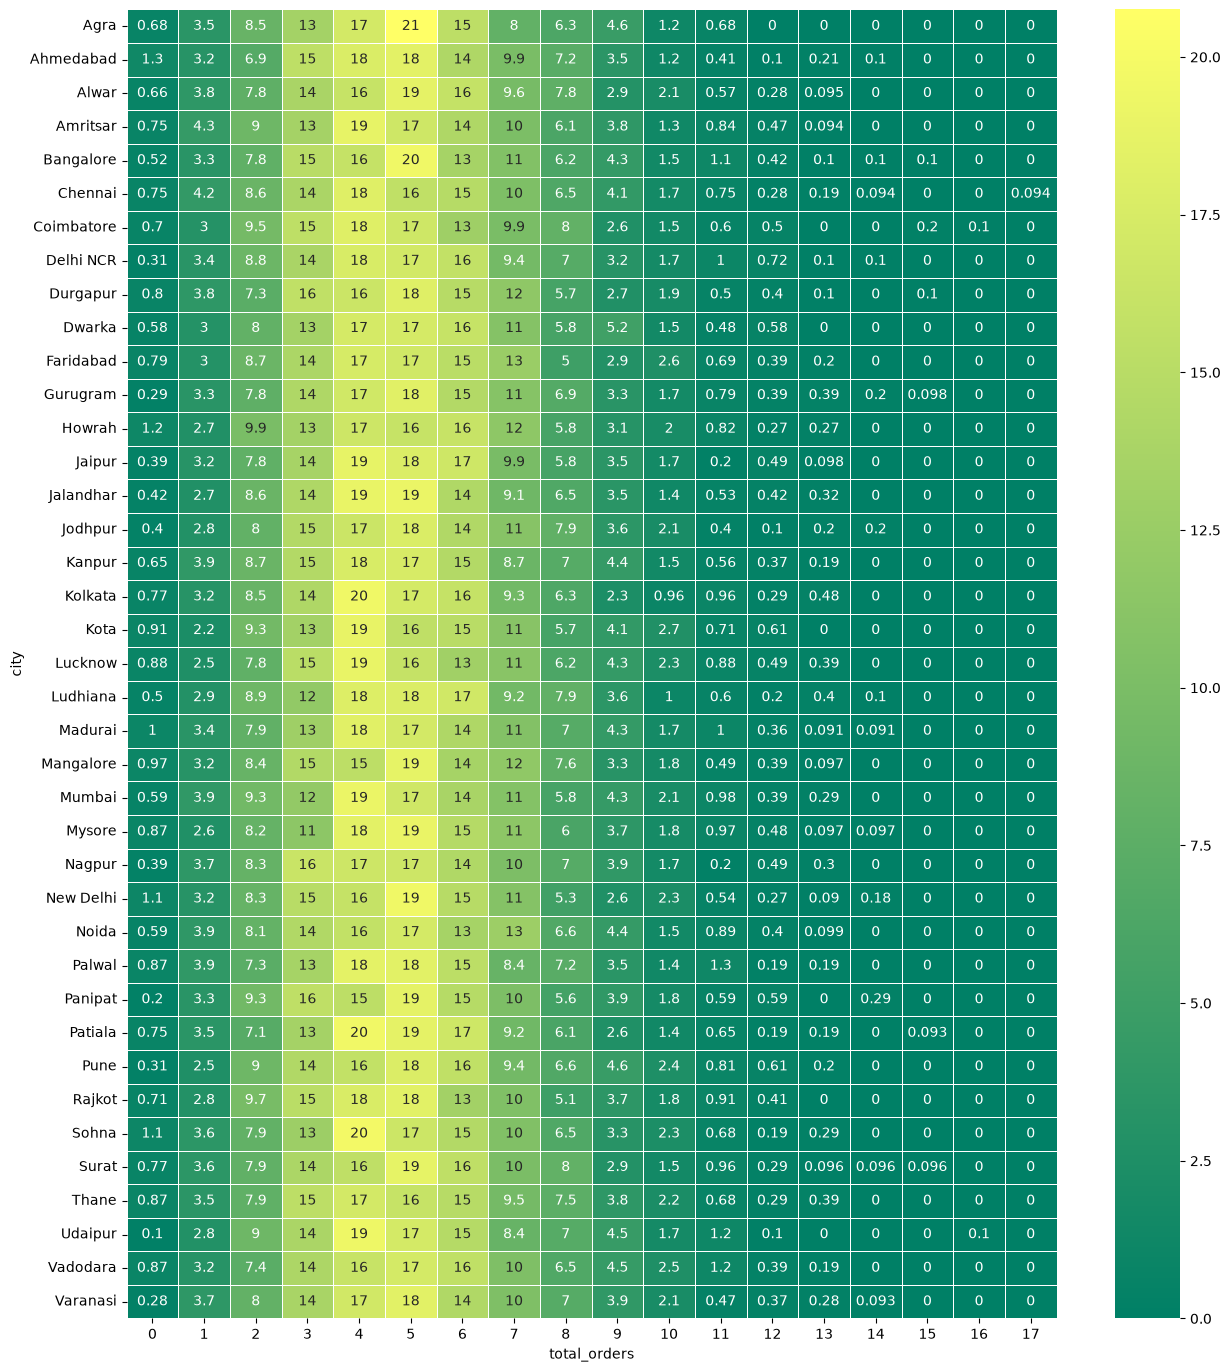

In [135]:
# City and Total_orders
grid = pd.crosstab(customers["city"], customers["total_orders"], normalize="index")*100
plt.figure(figsize=(15,17))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

* There is no relationship between the orders_placed and the city
* Across all cities, customer purchase frequency is concentrated between 2 and 8 total orders, accounting for roughly 85%–90% of the customer base, with order count 5 being the mode (~17%–21%)

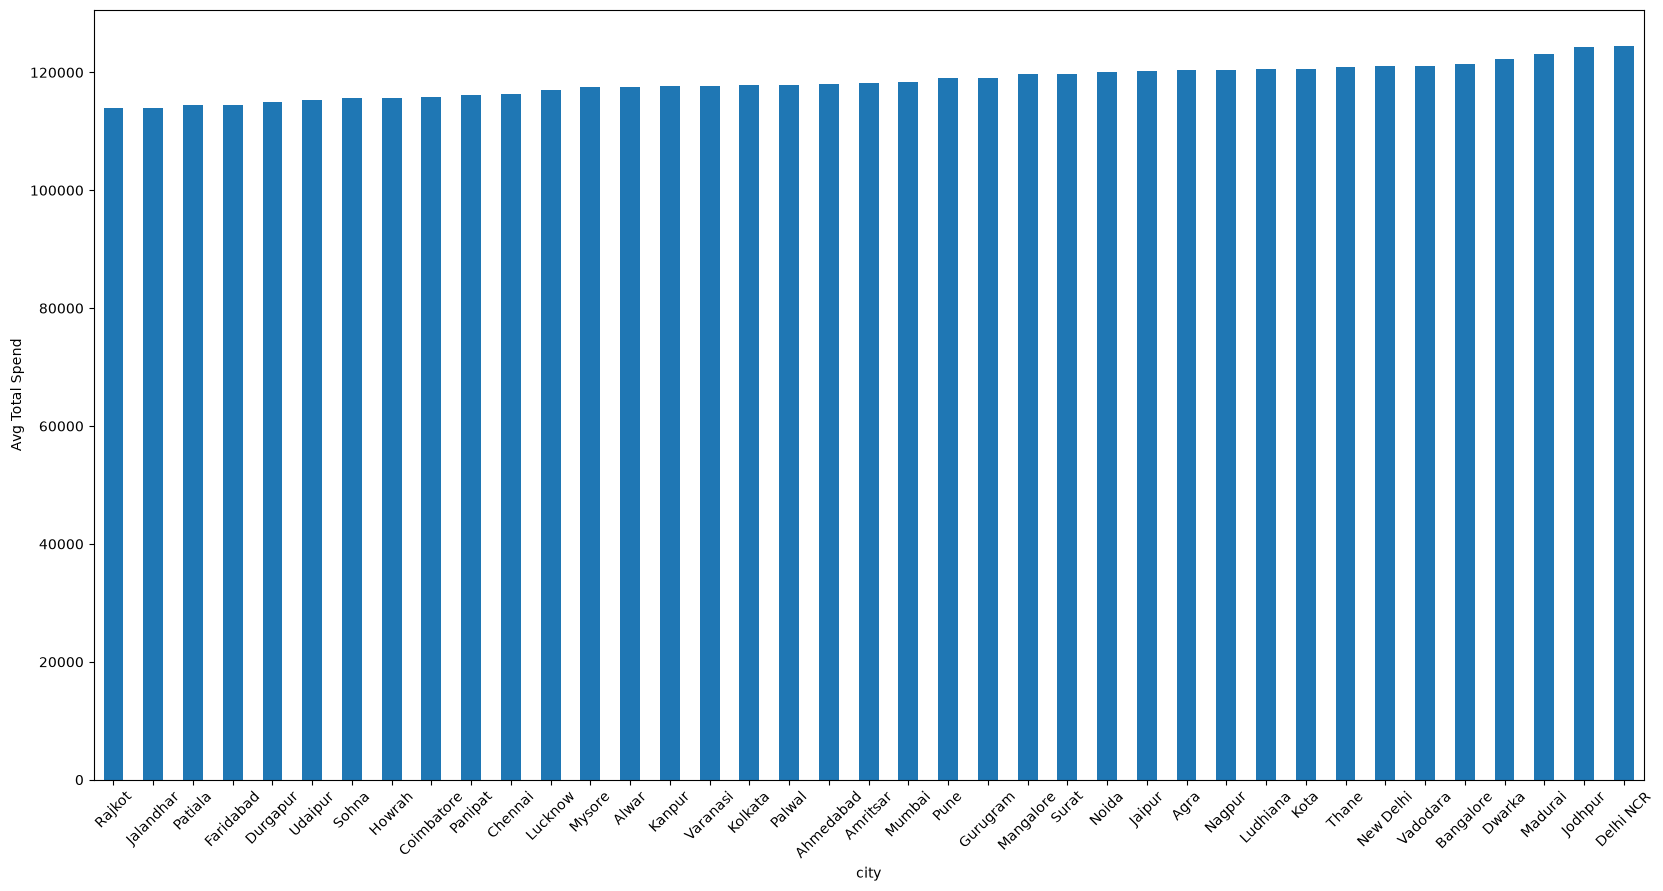

In [ ]:
# city and total spending
customers.groupby('city')['total_spent'].mean().sort_values(ascending=True).plot(kind='bar')
plt.ylabel("Avg Total Spend")
plt.xticks(rotation=45)
plt.show()

* There is no noticeable relationship between total spending and city
* Average total spend across all cities hovers tightly between ~114,000 and 124,000, indicating that geography does not drive customer purchasing power

<Axes: xlabel='customer_tier', ylabel='state'>

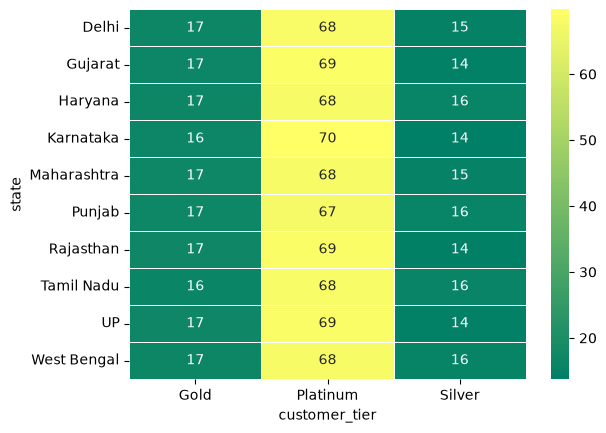

In [163]:
# state with customer_tire
grid = pd.crosstab(customers.state, customers.customer_tier, normalize="index")*100
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

<Axes: xlabel='total_orders', ylabel='state'>

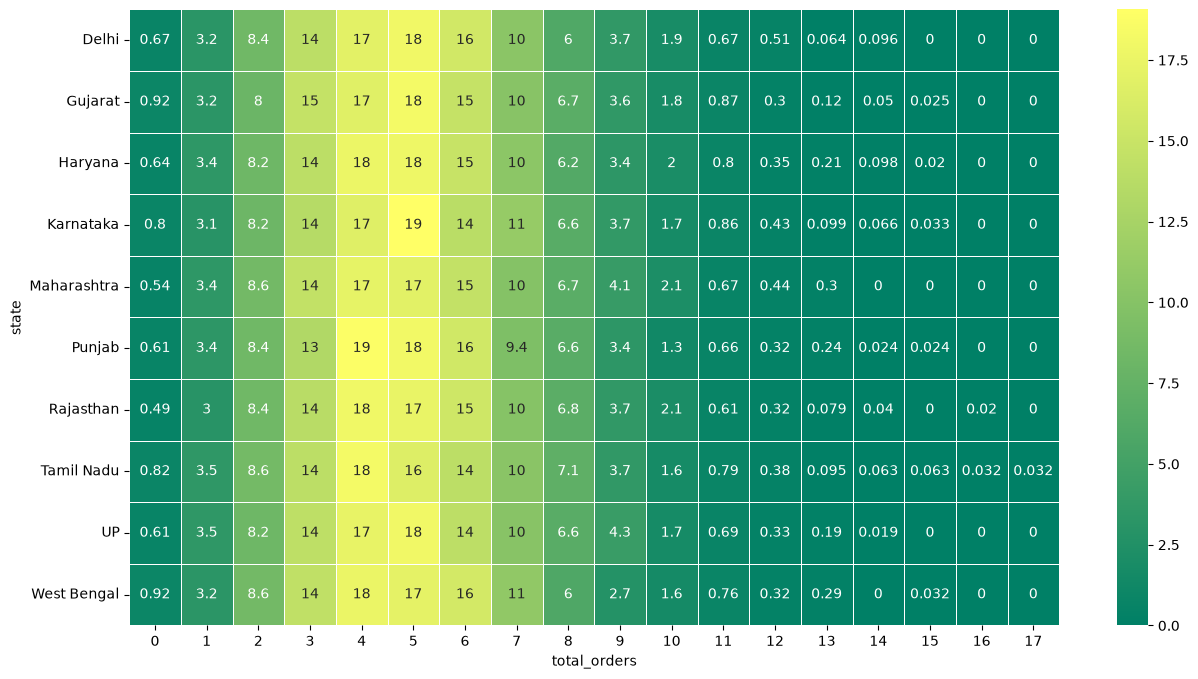

In [167]:
# State and Total_orders
grid = pd.crosstab(customers["state"], customers["total_orders"], normalize="index")*100
plt.figure(figsize=(15,8))
sns.heatmap(grid, annot=True, linewidth=0.5, cmap='summer')

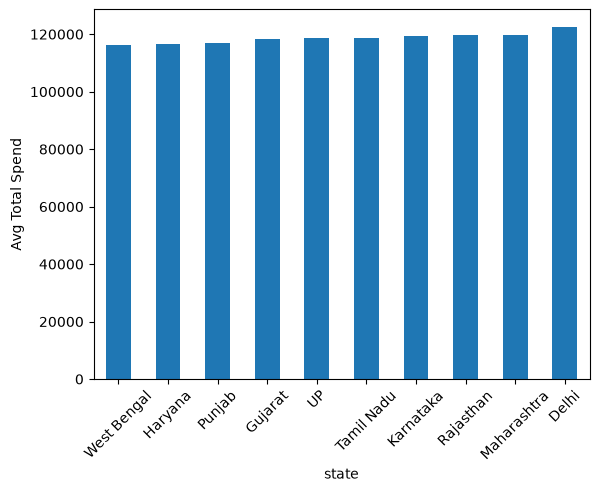

In [ ]:
# state and total spending
customers.groupby('state')['total_spent'].mean().sort_values(ascending=True).plot(kind='bar')
plt.ylabel("Avg Total Spend")
plt.xticks(rotation=45)
plt.show()

* No Geographic Dependency: There is no relationship between a customer's tier and the state in which they live.
* Consistent Distribution: Platinum accounts for roughly 68%-70% of memberships across all cities, while the remainder is split almost evenly between Gold and Silver.

* There is no relationship between the orders_placed and the state
* Across all cities, customer purchase frequency is concentrated between 2 and 7 total orders, accounting for roughly 85%–90% of the customer base, with order count 4 and 5 being the mode (~17%–20%)

* There is no noticeable relationship between total spending and state
* Average total spend across all cities hovers tightly between ~114,000 and 124,000, indicating that geography does not drive customer purchasing power